# Hoja de Trabajo 6 – Modelación y Simulación (CC2017)

**Grupo 11.** Conjunto $((11-1) \bmod 4)+1 = 3$: $\alpha_{12}=0.6$, $\alpha_{21}=1.5$; $r_1 = 1$, $r_2 = 0.5 + 0.1\,((11-1)\bmod 5) = 0.5$.

Modelo de competencia de Lotka–Volterra:
$$\dot x = r_1 x(1-x-\alpha_{12}y),\qquad \dot y = r_2 y(1-y-\alpha_{21}x)$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import sympy as sp

np.random.seed(11)   # semilla fija: todas las corridas son reproducibles
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Parámetros del grupo: conjunto = ((g-1) mod 4) + 1,  r2 = 0.5 + 0.1((g-1) mod 5)
g = 11
conjunto = ((g - 1) % 4) + 1
ALPHAS = {1: (0.5, 0.6), 2: (1.4, 1.5), 3: (0.6, 1.5), 4: (1.5, 0.6)}
a12, a21 = ALPHAS[conjunto]
r1 = 1.0
r2 = 0.5 + 0.1 * ((g - 1) % 5)
print(f"g = {g} | conjunto = {conjunto} | a12 = {a12}, a21 = {a21} | r1 = {r1}, r2 = {r2}")

# Estados iniciales de referencia
P = {"P1": (0.05, 0.05), "P2": (0.80, 0.30), "P3": (0.30, 0.80), "P4": (0.60, 0.60)}


def make_f(a12=a12, a21=a21, r1=r1, r2=r2):
    """Campo vectorial f(t, z) del modelo:
       x' = r1 x (1 - x - a12 y),   y' = r2 y (1 - y - a21 x).
    z puede ser (2,) o (2, N) para simular N estados iniciales a la vez."""
    def f(t, z):
        x, y = z
        return np.array([r1 * x * (1 - x - a12 * y), r2 * y * (1 - y - a21 * x)])
    return f


def jac(x, y, a12=a12, a21=a21, r1=r1, r2=r2):
    """Matriz jacobiana J = [[r1(1-2x-a12 y), -r1 a12 x], [-r2 a21 y, r2(1-2y-a21 x)]]."""
    return np.array([[r1 * (1 - 2 * x - a12 * y), -r1 * a12 * x],
                     [-r2 * a21 * y, r2 * (1 - 2 * y - a21 * x)]])


f = make_f()

g = 11 | conjunto = 3 | a12 = 0.6, a21 = 1.5 | r1 = 1.0, r2 = 0.5


## Task 1

In [2]:
# Task 1.1 — Equilibrios. SymPy SOLO verifica la derivación hecha a mano.
xs, ys, A12, A21, R1, R2 = sp.symbols("x y alpha12 alpha21 r1 r2")
F = sp.Matrix([R1 * xs * (1 - xs - A12 * ys), R2 * ys * (1 - ys - A21 * xs)])
for s in sp.solve(list(F), [xs, ys], dict=True):
    print("  (x*, y*) =", (sp.simplify(s[xs]), sp.simplify(s[ys])))

# Equilibrio interior derivado a mano: x* = (1-a12)/(1-a12 a21), y* = (1-a21)/(1-a12 a21)
def interior(a12, a21):
    d = 1 - a12 * a21
    return ((1 - a12) / d, (1 - a21) / d)

EQ = {"E0": (0.0, 0.0), "E1": (1.0, 0.0), "E2": (0.0, 1.0), "E3": interior(a12, a21)}
print("\nCon los parámetros del grupo:")
for k, (xe, ye) in EQ.items():
    fact = "factible" if (xe >= 0 and ye >= 0) else "NO factible"
    print(f"  {k} = ({xe:+.4f}, {ye:+.4f})  ->  {fact}")

  (x*, y*) = (0, 0)
  (x*, y*) = (0, 1)
  (x*, y*) = (1, 0)
  (x*, y*) = ((alpha12 - 1)/(alpha12*alpha21 - 1), (alpha21 - 1)/(alpha12*alpha21 - 1))

Con los parámetros del grupo:
  E0 = (+0.0000, +0.0000)  ->  factible
  E1 = (+1.0000, +0.0000)  ->  factible
  E2 = (+0.0000, +1.0000)  ->  factible
  E3 = (+4.0000, -5.0000)  ->  NO factible


In [3]:
# Task 1.2 — Jacobiana (verificación simbólica) y clasificación de cada equilibrio factible
print("J simbólica =", sp.simplify(F.jacobian([xs, ys])))

def clasificar(tau, det):
    """Clasificación por traza y determinante (plano tau-Delta)."""
    disc = tau**2 - 4 * det
    if det < 0:
        return "silla"
    est = "estable" if tau < 0 else "inestable"
    if disc >= 0:
        return f"nodo {est}"
    return "centro" if tau == 0 else f"foco {est}"

factibles = {k: v for k, v in EQ.items() if v[0] >= 0 and v[1] >= 0}
TD = {}
for k, (xe, ye) in factibles.items():
    J = jac(xe, ye)
    tau, det = np.trace(J), np.linalg.det(J)
    lam, V = np.linalg.eig(J)
    lam, V = np.real_if_close(lam), np.real_if_close(V)   # valores propios reales
    TD[k] = (tau, det)
    print(f"\n{k} = ({xe:g}, {ye:g})   J = {(J.round(4) + 0.0).tolist()}")
    print(f"   tau = {tau:+.4f}  Delta = {det:+.4f}  tau^2-4Delta = {tau**2 - 4*det:+.4f}")
    print(f"   lambda = {np.round(lam, 4)}  ->  {clasificar(tau, det)}")
    for i in range(2):
        print(f"   v(lambda={lam[i]:+.2f}) = {np.round(V[:, i] / np.max(np.abs(V[:, i])), 4)}")

# Solo como referencia: el equilibrio interior (no factible) también es una silla
xe, ye = EQ["E3"]
print(f"\nE3 (no factible): Delta = {np.linalg.det(jac(xe, ye)):+.4f}")

J simbólica = Matrix([[r1*(-alpha12*y - 2*x + 1), -alpha12*r1*x], [-alpha21*r2*y, r2*(-alpha21*x - 2*y + 1)]])

E0 = (0, 0)   J = [[1.0, 0.0], [0.0, 0.5]]
   tau = +1.5000  Delta = +0.5000  tau^2-4Delta = +0.2500
   lambda = [1.  0.5]  ->  nodo inestable
   v(lambda=+1.00) = [1. 0.]
   v(lambda=+0.50) = [0. 1.]

E1 = (1, 0)   J = [[-1.0, -0.6], [0.0, -0.25]]
   tau = -1.2500  Delta = +0.2500  tau^2-4Delta = +0.5625
   lambda = [-1.   -0.25]  ->  nodo estable
   v(lambda=-1.00) = [1. 0.]
   v(lambda=-0.25) = [-0.8  1. ]

E2 = (0, 1)   J = [[0.4, 0.0], [-0.75, -0.5]]
   tau = -0.1000  Delta = -0.2000  tau^2-4Delta = +0.8100
   lambda = [-0.5  0.4]  ->  silla
   v(lambda=-0.50) = [0. 1.]
   v(lambda=+0.40) = [ 1.     -0.8333]

E3 (no factible): Delta = -1.0000


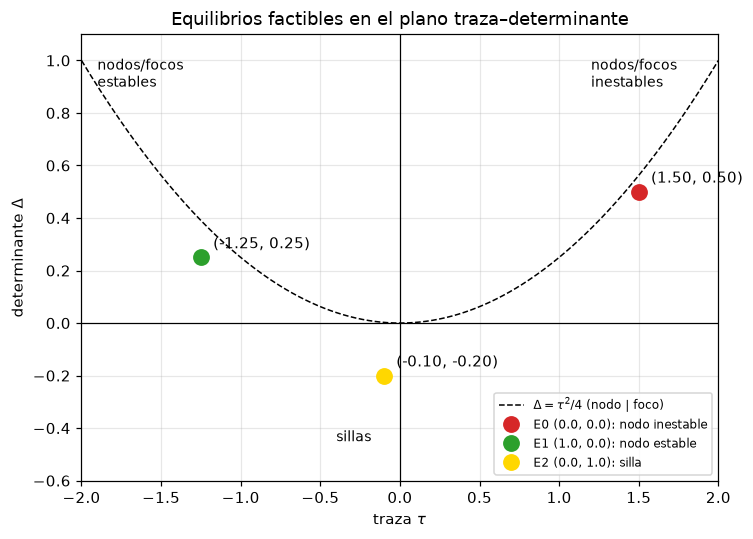

In [4]:
# Task 1.2c — Ubicación de los equilibrios en el plano traza-determinante
fig, ax = plt.subplots(figsize=(7, 5))
tt = np.linspace(-2, 2, 400)
ax.plot(tt, tt**2 / 4, "k--", lw=1, label=r"$\Delta = \tau^2/4$ (nodo | foco)")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
colores = {"E0": "tab:red", "E1": "tab:green", "E2": "gold"}
for k, (tau, det) in TD.items():
    ax.plot(tau, det, "o", ms=10, color=colores[k],
            label=f"{k} {factibles[k]}: {clasificar(tau, det)}")
    ax.annotate(f"({tau:.2f}, {det:.2f})", (tau, det), textcoords="offset points", xytext=(8, 6))
ax.text(-1.9, 0.9, "nodos/focos\nestables", fontsize=9)
ax.text(1.2, 0.9, "nodos/focos\ninestables", fontsize=9)
ax.text(-0.4, -0.45, "sillas", fontsize=9)
ax.set(xlim=(-2, 2), ylim=(-0.6, 1.1), xlabel=r"traza $\tau$", ylabel=r"determinante $\Delta$",
       title="Equilibrios factibles en el plano traza–determinante")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()